# Notebook 7 – High-Demand Warnings
A high-demand hour = demand above the 95th percentile of the previous 365 days (adaptive threshold, known at forecast time).
A warning is issued when the forecast exceeds threshold × (1 - margin). The margin is chosen on VALIDATION data
(model trained on 2019-2021) and then applied once to the test set. Metrics are reported per hour and per event.

In [1]:
import os, sys, json, subprocess, warnings
warnings.filterwarnings("ignore")
REPO = "India-Demand-Forecasting-ML"
BRANCH = "feature/tuning-warnings-dashboard"
URL = "https://github.com/tanishmaity03/India-Demand-Forecasting-ML.git"

# Colab: clone the branch. Local: if already inside the repo (or notebooks/ folder), just move to the repo root.
if not os.path.exists("src/peaks.py"):
    if os.path.exists("../src/peaks.py"):
        os.chdir("..")
    else:
        if not os.path.exists(REPO):
            subprocess.run(["git", "clone", "-b", BRANCH, URL], check=True)
        os.chdir(REPO)
print("Working directory:", os.getcwd())
# The branch above is missing src/features.py and src/evaluate.py (they live on feature/features-and-models): restore them.
for f in ("src/features.py", "src/evaluate.py"):
    if not os.path.exists(f):
        subprocess.run(["git", "fetch", "origin", "feature/features-and-models"], check=True)
        subprocess.run(["git", "checkout", "origin/feature/features-and-models", "--", f], check=True)
try:
    import holidays
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "holidays"], check=True)
sys.path.insert(0, ".")

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from src.features import build_features
from src.evaluate import split_mask
from src.peaks import MARGINS, warning_metrics, sweep

os.makedirs("results/tables", exist_ok=True); os.makedirs("results/figures", exist_ok=True)
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
df = pd.read_csv("data/processed/india_demand_weather.csv", parse_dates=["datetime"])
best = json.load(open("results/tables/best_params.json"))
demand = df.sort_values("datetime").set_index("datetime")["national"]
assert demand.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all(), "demand is not strictly hourly"
print({h: best[str(h)]["best_model"] for h in ("1", "24")})

Working directory: /content/India-Demand-Forecasting-ML
{'1': 'Gradient Boosting', '24': 'Random Forest'}


In [2]:
thr_origin = demand.rolling(24 * 365).quantile(0.95)     # known at the forecast origin, uses only the past 365 days
print(thr_origin.dropna().iloc[[0, -1]].round(0))

datetime
2019-12-31 23:00:00    169450.0
2024-04-30 23:00:00    212103.0
Name: national, dtype: float64


In [3]:
def make_model(name, params):
    if name == "Gradient Boosting":
        return HistGradientBoostingRegressor(early_stopping=False, random_state=42, **params)
    return RandomForestRegressor(max_samples=0.5, n_jobs=-1, random_state=42, **params)

chosen, sel_rows = {}, []
for h in (1, 24):
    ds = build_features(df, h, "full"); bm = best[str(h)]["best_model"]
    tr, va = split_mask(ds.target_time, "train"), split_mask(ds.target_time, "val")
    m = make_model(bm, best[str(h)][bm]).fit(ds.X[tr], ds.y_rel[tr])                # train-only model
    pred_val = m.predict(ds.X[va]) * ds.level[va].values
    thr_v = thr_origin.reindex(ds.X[va].index).values
    ok = ~np.isnan(thr_v)
    for method, p in ((bm, pred_val), ("Previous-day baseline", ds.baselines.loc[va, "previous_day"].values)):
        sw = sweep(ds.y_true[va].values[ok], p[ok], thr_v[ok])
        sw.insert(0, "method", method); sw.insert(0, "horizon_h", h); sel_rows.append(sw)
        chosen[(h, method)] = float(sw.loc[sw["F1"].idxmax(), "margin"])

sel = pd.concat(sel_rows).round(4)
sel.to_csv("results/tables/peak_warning_margin_selection_val.csv", index=False)
print(chosen)
sel[["horizon_h", "method", "margin", "precision", "recall", "F1"]]

{(1, 'Gradient Boosting'): 0.0, (1, 'Previous-day baseline'): 0.0, (24, 'Random Forest'): 0.0, (24, 'Previous-day baseline'): 0.0}


,horizon_h,method,margin,precision,recall,F1
0,1,Gradient Boosting,0.00,0.9268,0.9277,0.9272
1,1,Gradient Boosting,0.01,0.7853,0.9913,0.8764
2,1,Gradient Boosting,0.02,0.6506,1.0000,0.7883
3,1,Gradient Boosting,0.03,0.5398,1.0000,0.7011
4,1,Gradient Boosting,0.05,0.3786,1.0000,0.5493
0,1,Previous-day baseline,0.00,0.7627,0.7502,0.7564
1,1,Previous-day baseline,0.01,0.6738,0.8505,0.7519
2,1,Previous-day baseline,0.02,0.5727,0.8852,0.6955
3,1,Previous-day baseline,0.03,0.4966,0.9257,0.6465
4,1,Previous-day baseline,0.05,0.3675,0.9749,0.5338


In [4]:
perf, timelines = [], {}
for h in (1, 24):
    pr = pd.read_csv(f"results/predictions_test_h{h}.csv", parse_dates=["origin_time", "target_time"])
    bm = best[str(h)]["best_model"]; col = bm.lower().replace(" ", "_") + "_mw"
    thr = thr_origin.reindex(pr["origin_time"]).values
    assert not np.isnan(thr).any(), "threshold missing for some test origins"
    true_high = pr["actual_mw"].values > thr
    for method, p in ((bm, pr[col].values), ("Previous-day baseline", pr["previous_day_mw"].values)):
        m = chosen[(h, method)]; warn = p > thr * (1 - m)
        perf.append({"horizon_h": h, "method": method, "margin": m, "true_high_hours": int(true_high.sum()),
                     "base_rate_pct": true_high.mean() * 100, **warning_metrics(true_high, warn)})
        if method == bm:
            timelines[h] = pd.DataFrame({"target_time": pr["target_time"], "actual_mw": pr["actual_mw"], "predicted_mw": p,
                                         "threshold_mw": thr, "true_high": true_high.astype(int), "warning": warn.astype(int)})
perf = pd.DataFrame(perf).round(4)
perf.to_csv("results/tables/peak_warning_performance_test.csv", index=False)
for h, t in timelines.items():
    t.to_csv(f"results/peak_warnings_test_h{h}.csv", index=False)
perf

,horizon_h,method,margin,true_high_hours,base_rate_pct,TP,FP,FN,TN,precision,recall,F1,false_alarm_rate,true_episodes,episode_recall,warning_episodes,episode_precision
0,1,Gradient Boosting,0.0,1476,12.6543,1356,66,120,10122,0.9536,0.9187,0.9358,0.0065,243,0.9506,244,0.9549
1,1,Previous-day baseline,0.0,1476,12.6543,1089,373,387,9815,0.7449,0.7378,0.7413,0.0366,243,0.8066,245,0.8082
2,24,Random Forest,0.0,1486,12.7401,1149,225,337,9953,0.8362,0.7732,0.8035,0.0221,243,0.8560,245,0.8653
3,24,Previous-day baseline,0.0,1486,12.7401,1102,377,384,9801,0.7451,0.7416,0.7433,0.0370,243,0.8066,244,0.8074


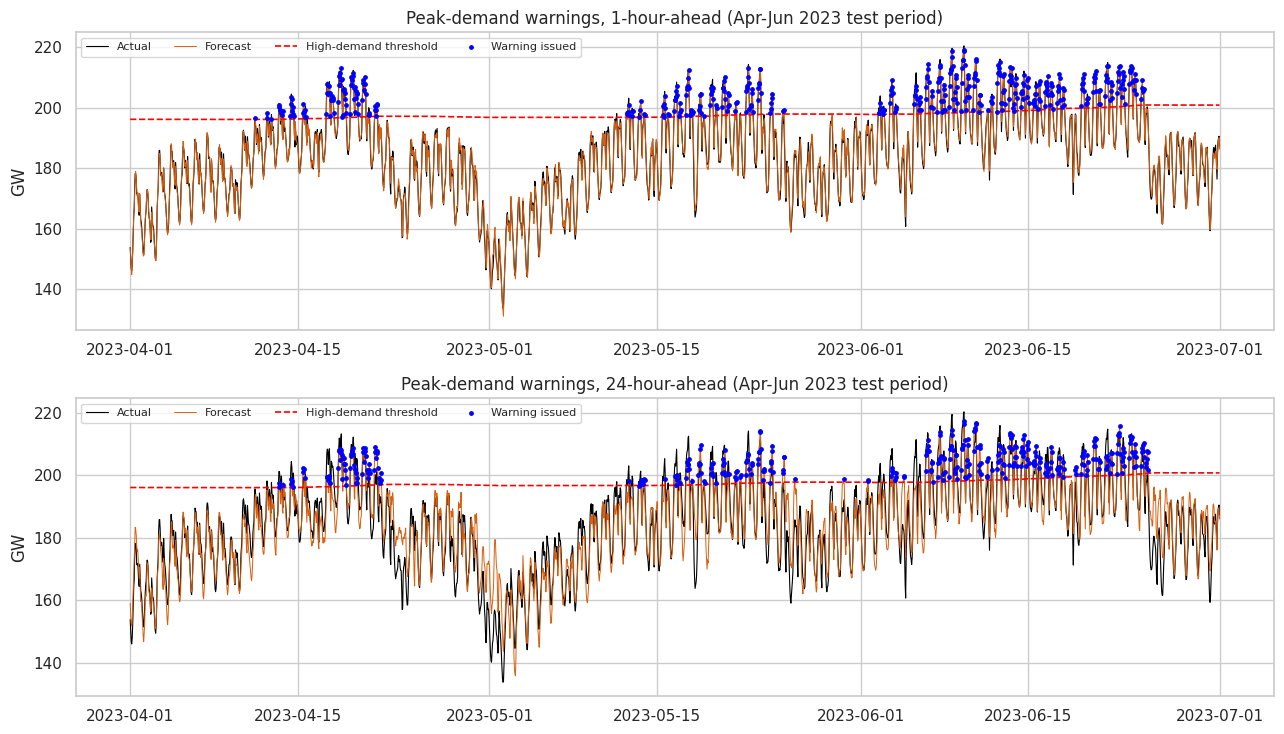

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5))
for ax, h in zip(axes, (1, 24)):
    t = timelines[h]; w = (t["target_time"] >= "2023-04-01") & (t["target_time"] < "2023-07-01"); t = t[w]
    ax.plot(t["target_time"], t["actual_mw"] / 1000, color="black", lw=0.8, label="Actual")
    ax.plot(t["target_time"], t["predicted_mw"] / 1000, color="#d95f0e", lw=0.7, label="Forecast")
    ax.plot(t["target_time"], t["threshold_mw"] / 1000, color="red", ls="--", lw=1.2, label="High-demand threshold")
    ax.scatter(t.loc[t["warning"] == 1, "target_time"], t.loc[t["warning"] == 1, "predicted_mw"] / 1000,
               s=6, color="blue", label="Warning issued", zorder=3)
    ax.set_title(f"Peak-demand warnings, {h}-hour-ahead (Apr-Jun 2023 test period)"); ax.set_ylabel("GW")
    ax.legend(loc="upper left", ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig("results/figures/07_peak_warnings_timeline.png", dpi=150); plt.show()

In [6]:
# Cell 7: findings, filled automatically from the tables above (no placeholders to edit)
from IPython.display import Markdown, display
def row(h, method): return perf[(perf.horizon_h == h) & (perf.method == method)].iloc[0]
lines = ["## Warning performance (test set)",
         f"- High-demand hours: {row(1, 'Previous-day baseline').base_rate_pct:.1f}% of test hours "
         "(threshold = 95th percentile of the previous 365 days; the rate exceeds 5% because the trailing threshold lags demand growth)."]
for h in (1, 24):
    bm = best[str(h)]["best_model"]; a, b = row(h, bm), row(h, "Previous-day baseline")
    lines.append(f"- {h} h ahead: {bm} (margin {a.margin:.0%}) detects {a.recall*100:.1f}% of high-demand hours (precision {a.precision:.2f}, F1 {a.F1:.2f}) "
                 f"and {a.episode_recall*100:.1f}% of {int(a.true_episodes)} high-demand episodes; "
                 f"previous-day baseline: recall {b.recall:.2f}, precision {b.precision:.2f}, F1 {b.F1:.2f}, episode recall {b.episode_recall:.2f}.")
lines += ["- The safety margin was selected on validation data (2022) only; test data was used once.",
          "- Limitation: the threshold definition and the 6-hour merging gap for episodes are modelling choices."]
display(Markdown("\n".join(lines)))

## Warning performance (test set)
- High-demand hours: 12.7% of test hours (threshold = 95th percentile of the previous 365 days; the rate exceeds 5% because the trailing threshold lags demand growth).
- 1 h ahead: Gradient Boosting (margin 0%) detects 91.9% of high-demand hours (precision 0.95, F1 0.94) and 95.1% of 243 high-demand episodes; previous-day baseline: recall 0.74, precision 0.74, F1 0.74, episode recall 0.81.
- 24 h ahead: Random Forest (margin 0%) detects 77.3% of high-demand hours (precision 0.84, F1 0.80) and 85.6% of 243 high-demand episodes; previous-day baseline: recall 0.74, precision 0.75, F1 0.74, episode recall 0.81.
- The safety margin was selected on validation data (2022) only; test data was used once.
- Limitation: the threshold definition and the 6-hour merging gap for episodes are modelling choices.

In [7]:
# Cell 8: package outputs (Colab downloads a zip; locally it just prints the path)
import shutil
shutil.make_archive("day4_warnings_outputs", "zip", ".", "results")
try:
    from google.colab import files
    files.download("day4_warnings_outputs.zip")
except ImportError:
    print("Saved:", os.path.abspath("day4_warnings_outputs.zip"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>